In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Visualization settings
sns.set_style('whitegrid')

In [73]:
df = pd.read_csv('customer_shopping_behavior_cleaned.csv')

In [74]:
df.head()

,Unnamed: 0,customer_id,age,gender,item_purchased,category,purchase_amount,location,size,color,season,review_rating,subscription_status,shipping_type,discount_applied,previous_purchases,payment_method,frequency_of_purchases,age_group,purchase_frequency_days
0,0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,14,Venmo,Fortnightly,Middle-aged,14
1,1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,2,Cash,Fortnightly,Young Adult,14
2,2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,23,Credit Card,Weekly,Middle-aged,7
3,3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,49,PayPal,Weekly,Young Adult,7
4,4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,31,PayPal,Annually,Middle-aged,365


In [75]:
df.shape

(3900, 20)

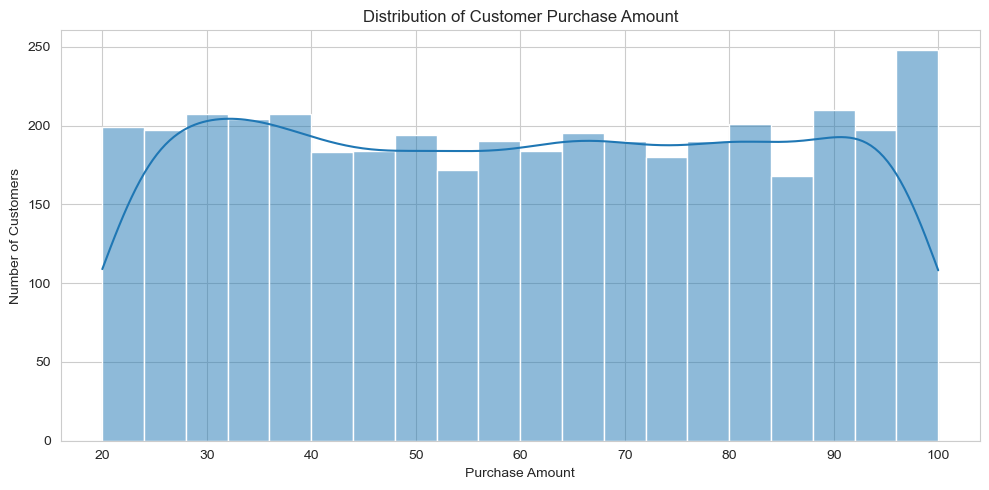

In [76]:
# Purchase Amount Distribution

plt.figure(figsize=(10, 5))

sns.histplot(data=df, x='purchase_amount', bins=20, kde=True)

plt.title('Distribution of Customer Purchase Amount')
plt.xlabel('Purchase Amount')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()


# Customers ne 20 se 100 tak har price range mein shopping ki hai.

Text(0, 0.5, 'Density')

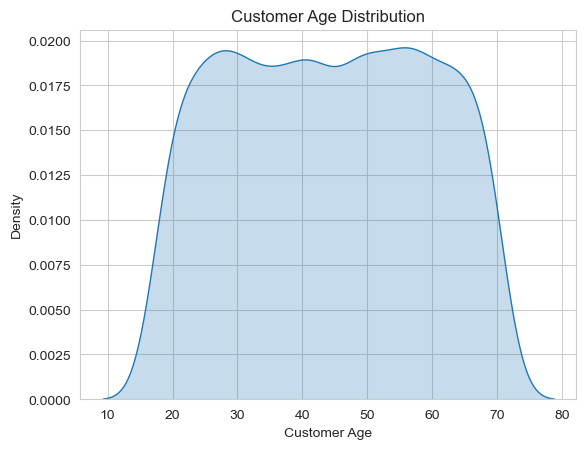

In [77]:
# Customer Age Distribution

sns.kdeplot(data=df, x='age', fill=True)
plt.title('Customer Age Distribution')
plt.xlabel('Customer Age')
plt.ylabel('Density')

# Hamare data mein har age ke customers approx. equal hain.

Text(0, 0.5, 'Number of Customers')

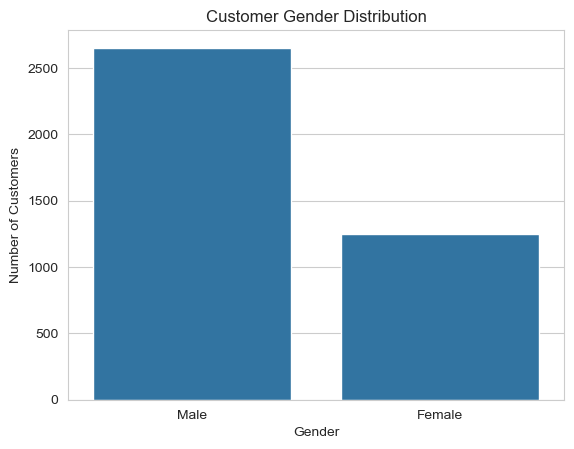

In [78]:
# Customer Gender Distributionabs

sns.countplot(data=df, x='gender')

plt.title('Customer Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')

# Male customers are more than female customers

Text(0, 0.5, 'Total Revenue')

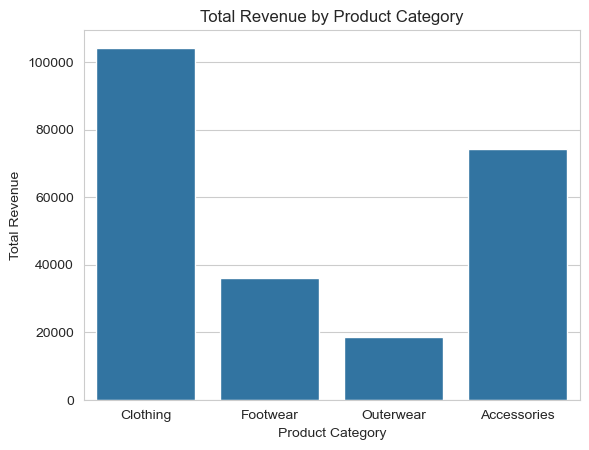

In [79]:
# Revenue by Product Category

sns.barplot(data=df, x='category', y='purchase_amount', estimator='sum', errorbar=None)

plt.title('Total Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')

# Clothing se sabse zyada aur Outerwear se sabse kam revenue aaya.

<Axes: xlabel='gender', ylabel='purchase_amount'>

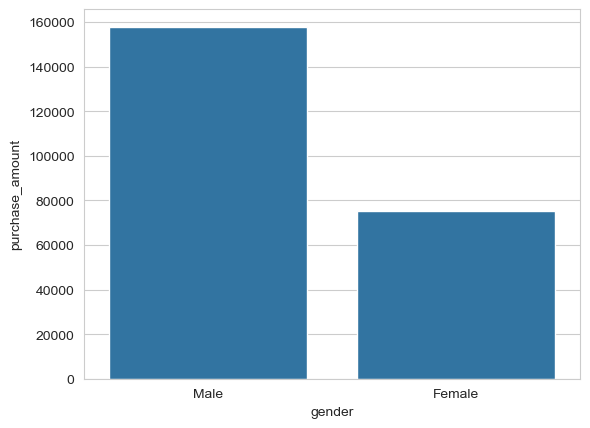

In [80]:
# Revenue by Gender

sns.barplot(data=df, x='gender', y='purchase_amount', estimator='sum', errorbar=None)



<Figure size 900x500 with 0 Axes>

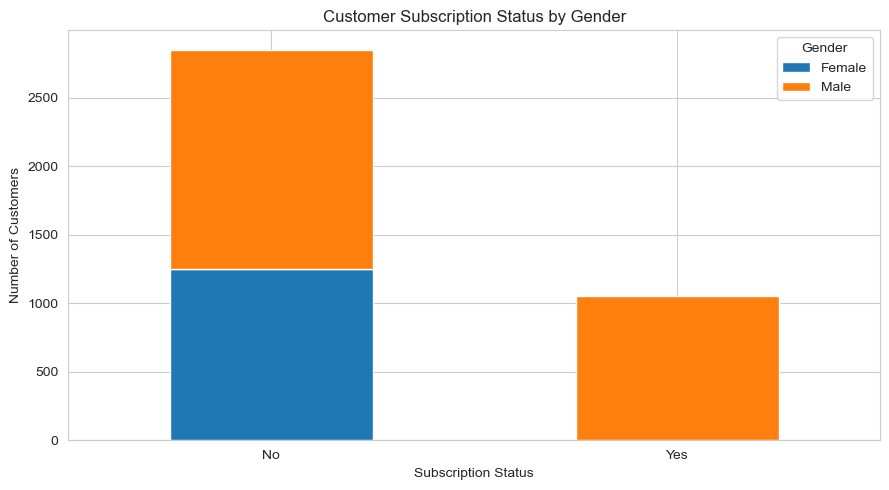

In [81]:
# Subscription Status vs Customer Count

subscription_gender = pd.crosstab(df['subscription_status'], df['gender'])

plt.figure(figsize=(9, 5))

subscription_gender.plot(kind='bar', stacked=True, figsize=(9, 5))

plt.title('Customer Subscription Status by Gender')
plt.xlabel('Subscription Status')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.legend(title='Gender')

plt.tight_layout()
plt.show()

# data mein male customers female customers se zyada subscription lete hain, aur non-subscribers ki count bhi zyada hai.

([0, 1, 2, 3, 4, 5],
 [Text(0, 0, '2-Day Shipping'),
  Text(1, 0, 'Express'),
  Text(2, 0, 'Free Shipping'),
  Text(3, 0, 'Next Day Air'),
  Text(4, 0, 'Standard'),
  Text(5, 0, 'Store Pickup')])

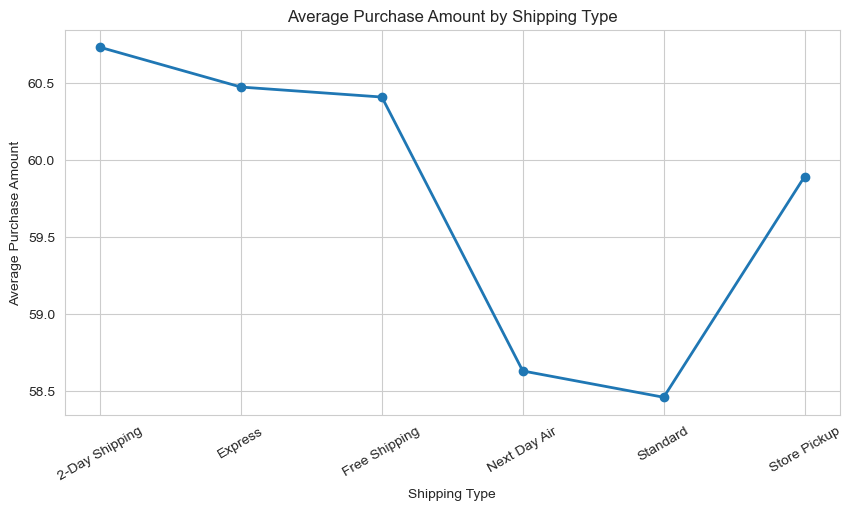

In [82]:
# Average Purchase Amount by Shipping Type
shipping_avg = df.groupby('shipping_type')['purchase_amount'].mean()

plt.figure(figsize=(10, 5))

plt.plot(shipping_avg.index, shipping_avg.values, marker='o', linewidth=2)

plt.title('Average Purchase Amount by Shipping Type')
plt.xlabel('Shipping Type')
plt.ylabel('Average Purchase Amount')
plt.xticks(rotation=30)

# data mein sabhi shipping types mein purchase amount ka distribution almost similar hai.

Text(0.5, 1.0, 'Correlation Between Numerical Features')

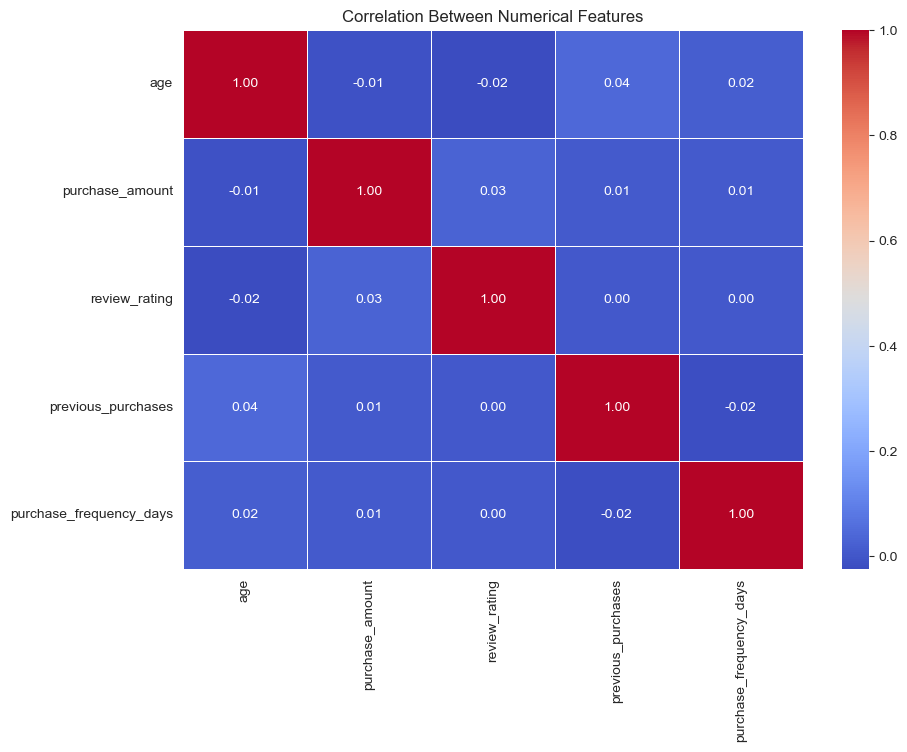

In [83]:
# Numerical Features Correlation (Heatmap)

correlation = df[['age', 'purchase_amount', 'review_rating', 'previous_purchases', 'purchase_frequency_days']].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)

plt.title('Correlation Between Numerical Features')

# plt.tight_layout()
# plt.show()


# data mein numerical features ke beech koi strong correlation nahi dikh rha.

([0, 1, 2, 3, 4, 5, 6],
 [Text(0, 0, 'Every 3 Months'),
  Text(1, 0, 'Annually'),
  Text(2, 0, 'Quarterly'),
  Text(3, 0, 'Monthly'),
  Text(4, 0, 'Bi-Weekly'),
  Text(5, 0, 'Fortnightly'),
  Text(6, 0, 'Weekly')])

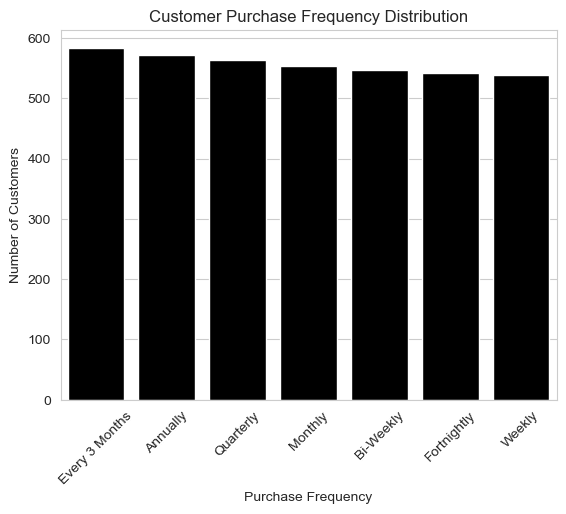

In [84]:
# Customer Purchase Frequency Distribution

sns.countplot(data=df, x='frequency_of_purchases', order=df['frequency_of_purchases'].value_counts().index, color='black')

plt.title('Customer Purchase Frequency Distribution')
plt.xlabel('Purchase Frequency')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)

# data mein sabhi purchase frequency categories ke customers almost equal hain.

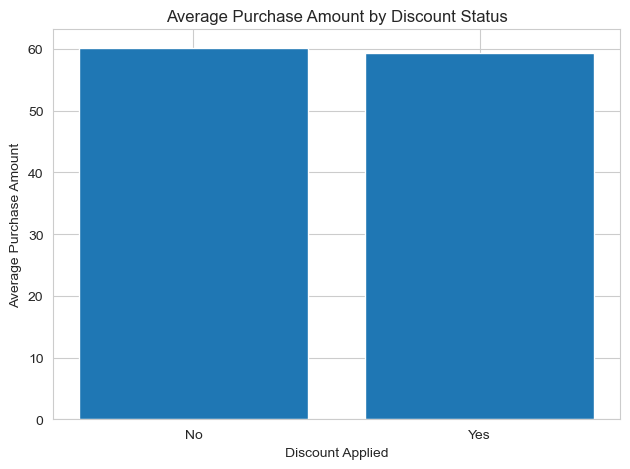

In [85]:
# Purchase Amount by Discount Status

discount_avg = df.groupby('discount_applied')['purchase_amount'].mean()

plt.bar(discount_avg.index, discount_avg.values)

plt.title('Average Purchase Amount by Discount Status')
plt.xlabel('Discount Applied')
plt.ylabel('Average Purchase Amount')

plt.tight_layout()
plt.show()

# data mein discount lene aur bina discount wale customers ka average spending almost same hai.

Text(0.5, 1.0, 'Revenue Contribution by Gender')

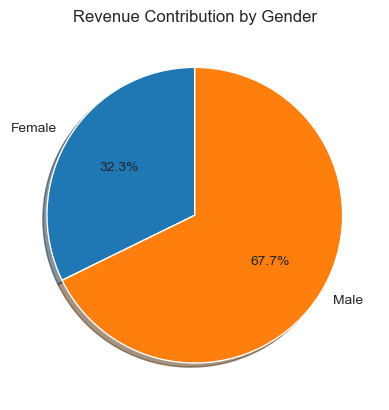

In [86]:
# Revenue Contribution by Gender

gender_revenue = df.groupby('gender')['purchase_amount'].sum()

plt.pie(gender_revenue.values, labels=gender_revenue.index, autopct='%1.1f%%', startangle=90, shadow=True)
plt.title('Revenue Contribution by Gender')

# data mein male customers ka revenue contribution 67.7% or female customers ka 32.3% hai.

Text(0, 0.5, 'Products')

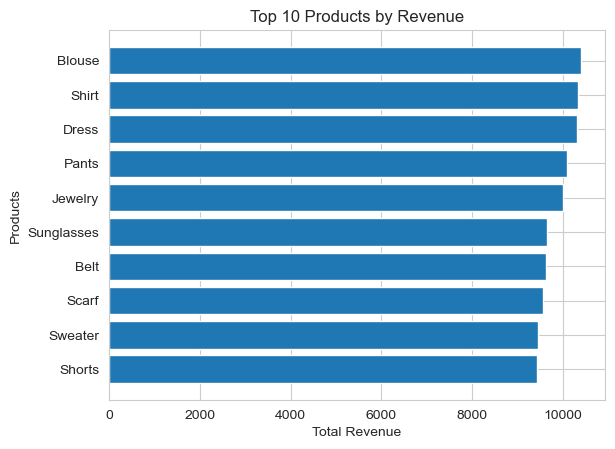

In [87]:
product_revenue = df.groupby('item_purchased')['purchase_amount'].sum().sort_values(ascending=True).tail(10)
plt.barh(product_revenue.index, product_revenue.values)

plt.title('Top 10 Products by Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Products')

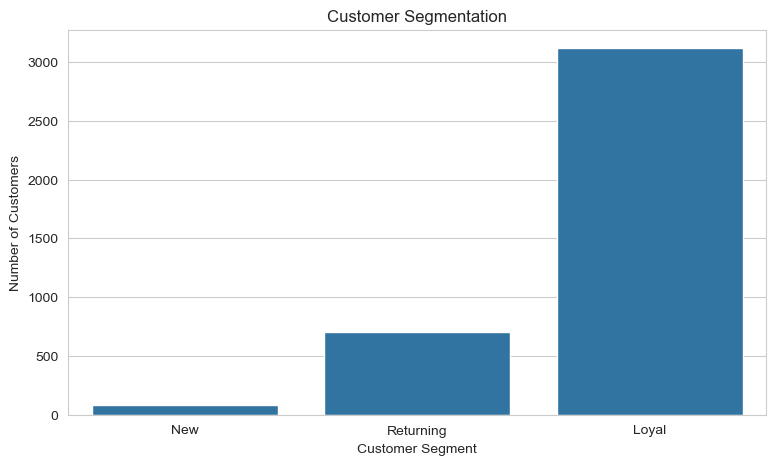

In [91]:
# Customer Segmentation (Count Plot)

df['customer_segment'] = pd.cut(df['previous_purchases'], bins=[0, 1, 10, float('inf')], labels=['New', 'Returning', 'Loyal'])

plt.figure(figsize=(9, 5))

sns.countplot(data=df, x='customer_segment', order=['New', 'Returning', 'Loyal'])

plt.title('Customer Segmentation')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')

plt.show()

# loyal customers are more

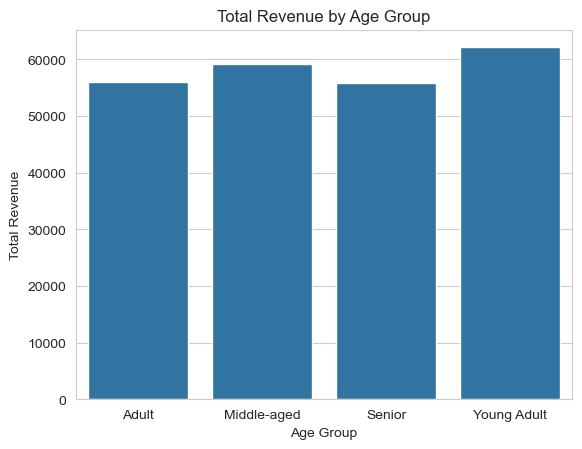

In [94]:
# Revenue by Age Group

age_revenue = df.groupby('age_group', observed=False)['purchase_amount'].sum().reset_index()

sns.barplot(data=age_revenue, x='age_group', y='purchase_amount')

plt.title('Total Revenue by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Total Revenue')

plt.show()

# Young adult are geerating more revenue in comparision of others

<Axes: xlabel='subscription_status', ylabel='purchase_amount'>

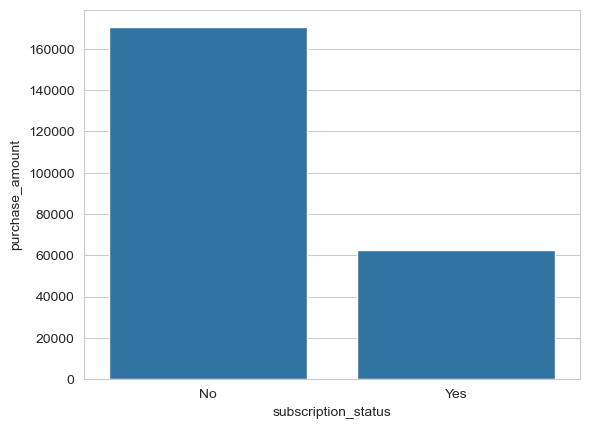

In [97]:
# Revenue by Subscription Status

subscription_revenue = df.groupby('subscription_status')['purchase_amount'].sum().reset_index()

sns.barplot(data=subscription_revenue, x='subscription_status', y='purchase_amount')

# data mein non-subscribers ka total revenue subscribers se kaafi zyada hai